# Actividad 2 · Segmentación de clientes

En esta actividad analizo qué clientes conviene retener, cuáles tienen oportunidad de comprar con mayor frecuencia y en qué casos valdría la pena intentar una reactivación. Para ello, aplico RFM y relaciono el comportamiento de compra con acciones comerciales y formas de medir sus resultados.

## 1. Datos y calidad

Comienzo comparando los archivos CSV y Excel de `datos/` para elegir una sola fuente de análisis. Los importes se expresan en **unidades monetarias (u.m.)**, porque no se especifica la moneda. Recency viene en días; la duración del período de Frequency y Monetary y la fecha de corte no están indicadas.

In [1]:
from pathlib import Path
import hashlib
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
datos = Path('datos')
rutas = [datos / 'retail_sales_dataset.csv', datos / 'retail_sales_dataset.xlsx']
hashes_iniciales = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in rutas}
print('Python:', platform.python_version())
print('Versiones:', {p: metadata.version(p) for p in ['pandas', 'numpy', 'matplotlib', 'openpyxl']})
display(pd.DataFrame({'archivo': list(hashes_iniciales), 'sha256': list(hashes_iniciales.values())}))

Python: 3.12.14
Versiones: {'pandas': '2.2.3', 'numpy': '2.3.5', 'matplotlib': '3.11.2', 'openpyxl': '3.1.5'}


,archivo,sha256
0,retail_sales_dataset.csv,0a724c78f2ec1f4937bd4bfd19558066d839b28ac2eab1...
1,retail_sales_dataset.xlsx,ea4dfbcf74f5139475955a3ea58016cf639e704d3b514c...


Registré las versiones de las bibliotecas y la huella de los archivos para poder reproducir el análisis y comprobar que los datos originales se conservan.

In [2]:
csv_original = pd.read_csv(rutas[0])
hojas_excel = pd.read_excel(rutas[1], sheet_name=None)
print('CSV:', csv_original.shape)
print('Hojas de Excel:', {nombre: tabla.shape for nombre, tabla in hojas_excel.items()})
print('Columnas CSV:', csv_original.columns.tolist())
display(csv_original.head())
display(csv_original.dtypes.rename('tipo').to_frame())
for nombre, tabla in hojas_excel.items():
    print(f'Primeras filas de Excel — {nombre}:')
    display(tabla.head(3))

CSV: (1000, 10)
Hojas de Excel: {'retail_sales_dataset': (1000, 10)}
Columnas CSV: ['ID', 'Customer ID', 'Region', 'Gender', 'Age', 'Product Category', 'Average ticket', 'Recency', 'Frequency', 'Monetary']


,ID,Customer ID,Region,Gender,Age,Product Category,Average ticket,Recency,Frequency,Monetary
0,1,CUST001,N,Male,34,Beauty,50,3,11,192.50
1,2,CUST002,E,Female,26,Clothing,500,11,3,450.00
2,3,CUST003,W,Male,50,Electronics,30,3,1,7.50
3,4,CUST004,E,Male,37,Clothing,500,9,4,700.00
4,5,CUST005,N,Male,30,Beauty,50,0,10,150.00


,tipo
ID,int64
Customer ID,object
Region,object
Gender,object
Age,int64
Product Category,object
Average ticket,int64
Recency,int64
Frequency,int64
Monetary,float64


Primeras filas de Excel — retail_sales_dataset:


,ID,Customer ID,Region,Gender,Age,Product Category,Average ticket,Recency,Frequency,Monetary
0,1,CUST001,N,Male,34,Beauty,50,3,11,192.50
1,2,CUST002,E,Female,26,Clothing,500,11,3,450.00
2,3,CUST003,W,Male,50,Electronics,30,3,1,7.50


Encontré **1,000 filas y 10 columnas** en ambos formatos. La base incluye `ID` y `Customer ID` como identificadores, y `Gender` utiliza las categorías `Male` y `Female`. Antes de analizar el comportamiento de compra, verifico que cada fila corresponda a un cliente distinto y que ambos archivos contengan los mismos datos.

In [3]:
excel_original = hojas_excel['retail_sales_dataset']
pd.testing.assert_frame_equal(
    csv_original.sort_values('Customer ID').reset_index(drop=True),
    excel_original.sort_values('Customer ID').reset_index(drop=True),
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
)
df = csv_original.copy(deep=True)
numericas = ['Age', 'Average ticket', 'Recency', 'Frequency', 'Monetary']
categoricas = ['Region', 'Gender', 'Product Category']
requeridas = ['Customer ID', *categoricas, *numericas]
assert set(requeridas).issubset(df.columns)

calidad = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'faltantes': df.isna().sum(),
    'valores_distintos': df.nunique(),
})
incidencias = pd.Series({
    'Filas duplicadas completas': int(df.duplicated().sum()),
    'Customer ID duplicados': int(df['Customer ID'].duplicated().sum()),
    'ID auxiliares duplicados': int(df['ID'].duplicated().sum()),
    'Celdas numéricas no finitas': int((~np.isfinite(df[numericas])).sum().sum()),
    'Edades fuera de 0–120 (alerta de plausibilidad)': int((~df['Age'].between(0,120)).sum()),
    'Recency negativo o no entero': int(((df.Recency < 0) | (df.Recency % 1 != 0)).sum()),
    'Frequency no positivo o no entero': int(((df.Frequency <= 0) | (df.Frequency % 1 != 0)).sum()),
    'Ticket o Monetary no positivos (para revisar)': int(((df['Average ticket'] <= 0) | (df.Monetary <= 0)).sum()),
    'Cadenas vacías o con espacios externos': int(sum(
        (df[c].str.strip().eq('') | df[c].ne(df[c].str.strip())).sum()
        for c in df.select_dtypes('object').columns)),
}, name='casos')
print('CSV y Excel coinciden en todos los clientes y columnas (tolerancia numérica 1e-12).')
display(calidad)
display(incidencias.to_frame())
for c in categoricas:
    print(c, sorted(df[c].unique()))
assert df[requeridas].notna().all().all() and df['Customer ID'].is_unique

CSV y Excel coinciden en todos los clientes y columnas (tolerancia numérica 1e-12).


,tipo,faltantes,valores_distintos
ID,int64,0,1000
Customer ID,object,0,1000
Region,object,0,4
Gender,object,0,2
Age,int64,0,47
Product Category,object,0,3
Average ticket,int64,0,5
Recency,int64,0,25
Frequency,int64,0,12
Monetary,float64,0,110


,casos
Filas duplicadas completas,0
Customer ID duplicados,0
ID auxiliares duplicados,0
Celdas numéricas no finitas,0
Edades fuera de 0–120 (alerta de plausibilidad),0
Recency negativo o no entero,0
Frequency no positivo o no entero,0
Ticket o Monetary no positivos (para revisar),0
Cadenas vacías o con espacios externos,0


Region ['E', 'N', 'S', 'W']
Gender ['Female', 'Male']
Product Category ['Beauty', 'Clothing', 'Electronics']


Los formatos coinciden y hay **1,000 clientes únicos**, sin faltantes, duplicados ni alertas en los rangos revisados. Uso el CSV como única entrada analítica; sumar ambos archivos duplicaría la misma población. Conservo todos los registros y las etiquetas originales. `ID` y `Customer ID` son identificadores, aunque el primero tenga tipo entero.

In [4]:
descriptivos = df[numericas].describe(percentiles=[.25,.5,.75,.9]).T
descriptivos['asimetria'] = df[numericas].skew()
display(descriptivos)

q1, q3 = df[numericas].quantile(.25), df[numericas].quantile(.75)
iqr = q3 - q1
fuera_iqr = ((df[numericas] < q1 - 1.5*iqr) | (df[numericas] > q3 + 1.5*iqr)).sum()
display(fuera_iqr.rename('casos_fuera_1_5_IQR').to_frame())
print('Frecuencias de los valores de ticket:')
display(df['Average ticket'].value_counts().sort_index().rename('clientes').to_frame())

# Relación entre Monetary, ticket y frecuencia.
ratio_monetary = df.Monetary / (df['Average ticket'] * df.Frequency)
display(ratio_monetary.round(8).value_counts().sort_index().rename('clientes').to_frame()
        .rename_axis('Monetary / (ticket × Frequency)'))

,count,mean,std,min,25%,50%,75%,90%,max,asimetria
Age,"1,000.00",41.39,13.68,18.00,29.00,42.00,53.00,60.00,64.00,-0.05
Average ticket,"1,000.00",179.89,189.68,25.00,30.00,50.00,300.00,500.00,500.00,0.74
Recency,"1,000.00",7.16,6.04,0.00,3.00,5.00,10.00,17.00,24.00,1.06
Frequency,"1,000.00",4.54,2.97,1.00,2.00,4.00,7.00,9.00,12.00,0.70
Monetary,"1,000.00",247.11,354.20,6.25,30.00,75.00,350.00,750.00,"2,100.00",2.17


,casos_fuera_1_5_IQR
Age,0
Average ticket,0
Recency,55
Frequency,0
Monetary,83


Frecuencias de los valores de ticket:


,clientes
Average ticket,
25,210
30,183
50,211
300,197
500,199


,clientes
Monetary / (ticket × Frequency),
0.25,333
0.30,333
0.35,334


La edad media es **41.39 años**. El ticket medio es **179.89 u.m.**, pero su mediana es **50**; solo toma cinco valores. Monetary tiene media **247.11** y mediana **75 u.m.**, con una cola de clientes de mayor valor.

La regla de 1.5 IQR señala 55 casos en Recency y 83 en Monetary. Los conservo: son observaciones para revisar, no errores demostrados, y eliminar valores altos borraría clientes relevantes para la segmentación.

El cociente `Monetary / (Average ticket × Frequency)` toma únicamente **25%, 30% y 35%**. Como Monetary ya incluye el margen, trabajo con ese valor sin aplicarle otra tasa ni multiplicarlo de nuevo por Frequency. La regularidad de los valores merece cautela al generalizar a un negocio real.

## 2. Comparación por región, género y categoría

La diferencia entre medias y medianas muestra que el valor de compra no se distribuye de manera uniforme. Ahora comparo región, género y categoría para identificar dónde se observan las mayores diferencias. Incluyo el tamaño de cada grupo y calculo promedios por cliente; `Average ticket` se promedia sin ponderar por número de compras.

In [5]:
resumenes = {}
for dimension in categoricas:
    resumen = df.groupby(dimension).agg(
        Clientes=('Customer ID','size'), Edad=('Age','mean'),
        Ticket=('Average ticket','mean'), Recency=('Recency','mean'),
        Frequency=('Frequency','mean'), Monetary=('Monetary','mean'),
    )
    resumen.insert(1, '% clientes', 100*resumen.Clientes/len(df))
    resumenes[dimension] = resumen
    print(dimension)
    display(resumen)

lideres = []
for dimension, tabla in resumenes.items():
    for metrica in ['Ticket','Frequency','Monetary']:
        orden = tabla[metrica].sort_values(ascending=False)
        lideres.append([dimension, metrica, orden.index[0], orden.iloc[0],
                        100*(orden.iloc[0]/orden.iloc[-1]-1)])
display(pd.DataFrame(lideres, columns=['Agrupación','Métrica','Grupo mayor',
                                     'Promedio mayor','Brecha vs menor (%)']))

Region


,Clientes,% clientes,Edad,Ticket,Recency,Frequency,Monetary
Region,,,,,,,
E,279,27.90,42.27,175.39,6.99,4.58,247.15
N,242,24.20,42.74,171.92,7.16,4.65,223.03
S,258,25.80,40.52,187.81,7.72,4.53,264.48
W,221,22.10,39.84,185.05,6.71,4.36,253.15


Gender


,Clientes,% clientes,Edad,Ticket,Recency,Frequency,Monetary
Gender,,,,,,,
Female,510,51.00,41.36,180.07,7.21,4.51,251.32
Male,490,49.00,41.43,179.70,7.11,4.56,242.73


Product Category


,Clientes,% clientes,Edad,Ticket,Recency,Frequency,Monetary
Product Category,,,,,,,
Beauty,307,30.70,40.37,184.06,3.03,6.34,344.37
Clothing,351,35.10,41.95,174.29,6.00,4.96,266.91
Electronics,342,34.20,41.74,181.90,12.05,2.48,139.49


,Agrupación,Métrica,Grupo mayor,Promedio mayor,Brecha vs menor (%)
0,Region,Ticket,S,187.81,9.24
1,Region,Frequency,N,4.65,6.67
2,Region,Monetary,S,264.48,18.58
3,Gender,Ticket,Female,180.07,0.20
4,Gender,Frequency,Male,4.56,1.19
5,Gender,Monetary,Female,251.32,3.54
6,Product Category,Ticket,Beauty,184.06,5.60
7,Product Category,Frequency,Beauty,6.34,155.21
8,Product Category,Monetary,Beauty,344.37,146.88


Por región, **S** tiene el mayor ticket (**187.81**) y Monetary (**264.48 u.m.**); **N** tiene la mayor frecuencia (**4.65**). Las diferencias por género son pequeñas: el ticket difiere apenas 0.20% entre el grupo mayor y el menor.

La categoría presenta una separación más clara. **Beauty** encabeza ticket (**184.06**), frecuencia (**6.34**) y Monetary (**344.37**). Electronics registra **2.48 compras** y **139.49 u.m.**, con una recencia media de **12.05 días**, frente a **3.03** en Beauty. Esto me lleva a usar la categoría para interpretar el ciclo de recompra, antes de atribuir esas diferencias a lealtad o abandono. Son comparaciones descriptivas, sin afirmar causalidad.

## 3. Distribuciones RFM

Las diferencias por categoría hacen necesario revisar las tres dimensiones antes de asignar puntajes. En Recency, menos días significa una compra más reciente; en Frequency y Monetary, valores mayores indican más compras y mayor valor histórico. Revisaré cómo se distribuyen para establecer referencias dentro de esta base.

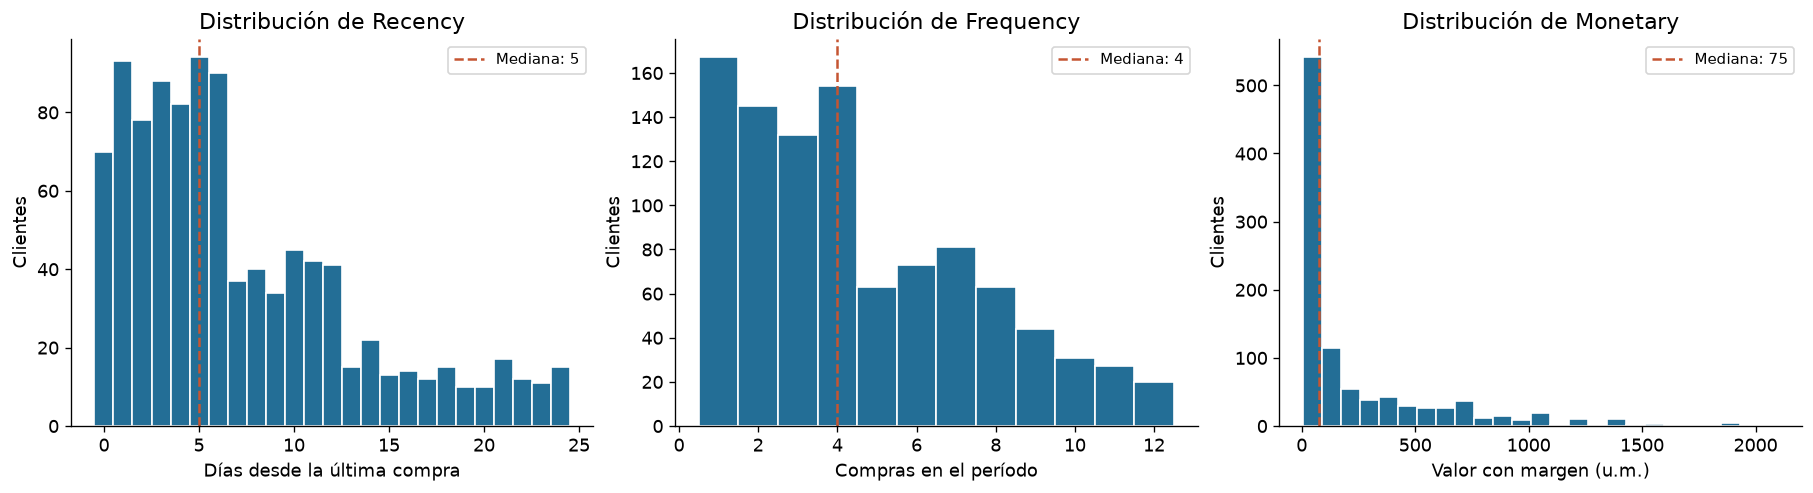

,Recency,Frequency,Monetary
Cuantil,,,
0.00,0.00,1.00,6.25
0.20,2.00,2.00,25.00
0.40,4.00,3.00,56.25
0.50,5.00,4.00,75.00
0.60,7.00,5.00,120.00
0.80,12.00,7.00,450.00
1.00,24.00,12.00,"2,100.00"


Correlaciones de Spearman (asociación de rangos):


,Recency,Frequency,Monetary,Average ticket
Recency,1.00,-0.29,-0.12,0.03
Frequency,-0.29,1.00,0.52,0.01
Monetary,-0.12,0.52,1.00,0.81
Average ticket,0.03,0.01,0.81,1.00


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15,4), layout='constrained')
etiquetas_rfm = {'Recency':'Días desde la última compra',
                 'Frequency':'Compras en el período', 'Monetary':'Valor con margen (u.m.)'}
for ax, variable in zip(axes, etiquetas_rfm):
    serie = df[variable]
    bins = np.arange(serie.min()-.5, serie.max()+1.5) if variable != 'Monetary' else 25
    ax.hist(serie, bins=bins, color='#236E96', edgecolor='white')
    ax.axvline(serie.median(), color='#C55532', linestyle='--', label=f'Mediana: {serie.median():g}')
    ax.set(title=f'Distribución de {variable}', xlabel=etiquetas_rfm[variable], ylabel='Clientes')
    ax.legend(fontsize=9)
plt.show()
display(df[['Recency','Frequency','Monetary']].quantile([0,.2,.4,.5,.6,.8,1]).rename_axis('Cuantil'))
print('Correlaciones de Spearman (asociación de rangos):')
display(df[['Recency','Frequency','Monetary','Average ticket']].corr(method='spearman'))

En Recency, la mediana es **5 días** y el percentil 80 es **12**: una recencia alta solo es alta respecto a esta base, cuyo máximo es 24 días. Frequency tiene mediana **4 compras**; su percentil 80 es **7**. Monetary muestra la mayor asimetría: mediana **75** frente a percentil 80 de **450 u.m.**

La asociación de Monetary es más fuerte con el ticket (**Spearman 0.81**) que con Frequency (**0.52**). No basta con buscar quién compra más veces: también importa el valor de esas compras. Parte de esta relación es esperable por la construcción monetaria observada.

## 4. Puntajes RFM

Uso los percentiles 20, 40, 60 y 80 de toda la base, para establecer cinco niveles en cada dimensión. Los valores iguales reciben el mismo puntaje; por eso los grupos pueden tener tamaños distintos. Cada corte se incluye en el intervalo inferior: en Frequency y Monetary recibe el puntaje menor; en Recency, al invertir la escala, recibe el mejor.

Los cortes sirven para comparar clientes en esta fotografía. Para seguimiento de campañas habría que conservarlos durante la evaluación, evitando que un cambio de población altere los puntajes por sí solo. `RFM_Score` concatena R–F–M; no se interpreta como una suma ni como una distancia numérica.

In [7]:
variables_rfm = ['Recency','Frequency','Monetary']
columnas_score = ['R_Score','F_Score','M_Score']
cortes = df[variables_rfm].quantile([.2,.4,.6,.8])
rfm = df.copy(deep=True)
for variable, score in zip(variables_rfm, columnas_score):
    limites = [-np.inf, *cortes[variable].tolist(), np.inf]
    assert pd.Series(limites).is_unique, f'Cortes repetidos en {variable}: revisar método'
    etiquetas = [5,4,3,2,1] if variable == 'Recency' else [1,2,3,4,5]
    rfm[score] = pd.cut(rfm[variable], bins=limites, labels=etiquetas,
                        right=True).astype(int)
rfm['RFM_Score'] = rfm[columnas_score].astype(str).agg(''.join, axis=1)

intervalos = []
for variable, score in zip(variables_rfm, columnas_score):
    tabla = rfm.groupby(score)[variable].agg(Minimo='min', Maximo='max', Clientes='size')
    tabla['% clientes'] = 100*tabla.Clientes/len(rfm)
    tabla.insert(0, 'Variable', variable)
    intervalos.append(tabla.rename_axis('Puntaje').reset_index())
display(cortes.rename_axis('Percentil'))
display(pd.concat(intervalos, ignore_index=True))

for variable, score in zip(variables_rfm, columnas_score):
    pares = rfm[[variable,score]].drop_duplicates().sort_values(variable)
    assert pares[variable].is_unique  # ningún empate se divide entre puntajes
    assert (pares[score].is_monotonic_decreasing if variable=='Recency'
            else pares[score].is_monotonic_increasing)
    assert rfm[score].between(1,5).all()
print('RFM distintos:', rfm.RFM_Score.nunique())
print('Clientes 555:', int(rfm.RFM_Score.eq('555').sum()))

,Recency,Frequency,Monetary
Percentil,,,
0.20,2.00,2.00,25.00
0.40,4.00,3.00,56.25
0.60,7.00,5.00,120.00
0.80,12.00,7.00,450.00


,Puntaje,Variable,Minimo,Maximo,Clientes,% clientes
0,1,Recency,13.00,24.00,166,16.60
1,2,Recency,8.00,12.00,202,20.20
2,3,Recency,5.00,7.00,221,22.10
3,4,Recency,3.00,4.00,170,17.00
4,5,Recency,0.00,2.00,241,24.10
5,1,Frequency,1.00,2.00,312,31.20
6,2,Frequency,3.00,3.00,132,13.20
7,3,Frequency,4.00,5.00,217,21.70
8,4,Frequency,6.00,7.00,154,15.40
9,5,Frequency,8.00,12.00,185,18.50


RFM distintos: 95
Clientes 555: 20


Los cortes son **2, 4, 7 y 12 días** para R; **2, 3, 5 y 7 compras** para F; y **25, 56.25, 120 y 450 u.m.** para M. Por ejemplo, una recencia de 2 días recibe R=5 y una de 13 días, R=1.

Los empates importan: **31.2%** de los clientes tiene un puntaje F=1 porque registra una o dos compras. Mantener el mismo puntaje para el mismo comportamiento me parece más defendible que separar clientes por su orden en el archivo para forzar grupos de 20%. Hay **95 códigos RFM** y **20 clientes 555**; un segmento puede reunir varios códigos.

## 5. Segmentos accionables

Agrupo los puntajes en seis segmentos para asociar cada perfil con una decisión comercial. “Reciente”, “alto” y “bajo” son relativos a los puntajes globales. Uso **En riesgo de alto valor** como una señal para revisar clientes valiosos menos recientes, sin dar por confirmado el abandono. Tampoco llamo “nuevos” a los compradores ocasionales: no tenemos fecha de alta ni primera compra.

| Segmento | Regla | Lectura comercial |
| --- | --- | --- |
| Campeones | R ≥ 4, F ≥ 4, M ≥ 4 | Compra reciente, recurrente y de alto valor. |
| Leales | R ≥ 3, F ≥ 4, excluyendo Campeones | Recurrencia alta; cuidar la relación y desarrollar valor. |
| Potenciales | R ≥ 3, F ≤ 3, M ≥ 3 | Valor medio/alto con espacio para desarrollar frecuencia. |
| Ocasionales recientes | R ≥ 3, F ≤ 3, M ≤ 2 | Compra relativamente reciente, menor recurrencia y valor. |
| En riesgo de alto valor | R ≤ 2 y (F ≥ 4 o M ≥ 4) | Historial valioso que conviene revisar y recuperar si procede. |
| Baja actividad y valor | R ≤ 2, F ≤ 3, M ≤ 3 | Menor prioridad de inversión según el historial disponible. |

Uso `F ≥ 4 o M ≥ 4` en riesgo para conservar tanto compradores frecuentes como compradores de alto valor, incluso cuando solo una de esas dimensiones es elevada.

In [8]:
segmentos = ['Campeones','Leales','Potenciales','Ocasionales recientes',
             'En riesgo de alto valor','Baja actividad y valor']
def clasificar_segmentos(tabla):
    r,f,m = (tabla[c] for c in columnas_score)
    campeones = (r>=4) & (f>=4) & (m>=4)
    reglas = [campeones,
              (r>=3) & (f>=4) & ~campeones,
              (r>=3) & (f<=3) & (m>=3),
              (r>=3) & (f<=3) & (m<=2),
              (r<=2) & ((f>=4) | (m>=4)),
              (r<=2) & (f<=3) & (m<=3)]
    assert np.vstack(reglas).sum(axis=0).tolist() == [1]*len(tabla)
    return pd.Series(np.select(reglas, segmentos, default='Sin asignar'), index=tabla.index)

rfm['Segmento'] = clasificar_segmentos(rfm)
conteos = rfm.Segmento.value_counts().reindex(segmentos, fill_value=0)
display(pd.DataFrame({'Clientes':conteos, '% clientes':100*conteos/len(rfm)}))

# Un ejemplo de cada segmento, conservando el orden de entrada.
ejemplos = rfm.groupby('Segmento',sort=False).head(1).set_index('Segmento').reindex(segmentos)
display(ejemplos[['Customer ID', *variables_rfm, *columnas_score, 'RFM_Score']])
print('Cobertura:', len(rfm), 'clientes; sin asignaciones múltiples ni clientes omitidos.')

,Clientes,% clientes
Segmento,,
Campeones,92,9.20
Leales,194,19.40
Potenciales,162,16.20
Ocasionales recientes,184,18.40
En riesgo de alto valor,156,15.60
Baja actividad y valor,212,21.20


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Segmento,,,,,,,,
Campeones,CUST001,3,11,192.50,4,5,4,454
Leales,CUST011,2,8,120.00,5,5,3,553
Potenciales,CUST021,6,3,375.00,3,2,4,324
Ocasionales recientes,CUST003,3,1,7.50,4,1,1,411
En riesgo de alto valor,CUST002,11,3,450.00,2,2,4,224
Baja actividad y valor,CUST008,8,4,30.00,2,3,2,232


Cobertura: 1000 clientes; sin asignaciones múltiples ni clientes omitidos.


Los seis grupos cubren los **1,000 clientes** una sola vez. Hay **92 Campeones**, pero solo 20 clientes 555: los criterios que elegí admiten distintos perfiles altos, como CUST001 (454). CUST002 (224) entra en riesgo por su valor monetario alto y menor puntaje de recencia, aunque su frecuencia sea baja.

El grupo mayor es **Baja actividad y valor (21.2%)**, sin dominar por sí solo la base. El nombre describe el historial observado, no el potencial futuro de sus integrantes.

## 6. Perfil de los segmentos

Una vez clasificados los clientes, comparo el tamaño, el comportamiento y la contribución de cada grupo para decidir dónde concentrar el esfuerzo comercial. Incluyo la participación de la región y categoría predominantes dentro de cada segmento, conservando todas las modas si hay empate.

In [9]:
def predominante(serie):
    frecuencias = serie.value_counts()
    lideres = frecuencias[frecuencias == frecuencias.max()].index.tolist()
    return ' / '.join(sorted(lideres)) + f' ({100*frecuencias.max()/len(serie):.1f}%)'

perfil = rfm.groupby('Segmento').agg(
    Clientes=('Customer ID','size'), Edad=('Age','mean'),
    Ticket=('Average ticket','mean'), Recency=('Recency','mean'),
    Frequency=('Frequency','mean'), Monetary=('Monetary','mean'),
    Monetary_total=('Monetary','sum'),
    Categoria=('Product Category',predominante), Region=('Region',predominante),
).reindex(segmentos)
perfil.insert(1, '% clientes', 100*perfil.Clientes/len(rfm))
perfil['% Monetary'] = 100*perfil.Monetary_total/rfm.Monetary.sum()
display(perfil[['Clientes','% clientes','Edad','Ticket','Recency','Frequency',
                'Monetary','Categoria','Region','% Monetary']])
print('Monetary total:', f'{rfm.Monetary.sum():,.2f}', 'u.m.')
print('Categoría por segmento (% dentro de cada segmento):')
composicion = pd.crosstab(rfm.Segmento, rfm['Product Category'], normalize='index').reindex(segmentos)*100
display(composicion)

,Clientes,% clientes,Edad,Ticket,Recency,Frequency,Monetary,Categoria,Region,% Monetary
Segmento,,,,,,,,,,
Campeones,92,9.20,40.34,308.48,2.05,8.68,788.46,Beauty (71.7%),N (29.3%),29.35
Leales,194,19.40,41.76,115.72,3.85,8.11,283.60,Beauty (55.7%),E (29.9%),22.26
Potenciales,162,16.20,40.54,358.64,3.57,3.19,331.17,Beauty (40.1%),E (27.2%),21.71
Ocasionales recientes,184,18.40,40.92,33.02,3.24,2.43,22.71,Beauty (37.0%),E (27.7%),1.69
En riesgo de alto valor,156,15.60,42.04,331.44,12.97,4.33,348.77,Electronics (53.8%),S (26.9%),22.02
Baja actividad y valor,212,21.20,42.10,62.17,14.28,2.47,34.52,Electronics (71.7%),E (29.2%),2.96


Monetary total: 247,113.00 u.m.
Categoría por segmento (% dentro de cada segmento):


Product Category,Beauty,Clothing,Electronics
Segmento,,,
Campeones,71.74,28.26,0.00
Leales,55.67,44.33,0.00
Potenciales,40.12,33.95,25.93
Ocasionales recientes,36.96,28.26,34.78
En riesgo de alto valor,0.00,46.15,53.85
Baja actividad y valor,0.00,28.30,71.70


Los Campeones representan **9.2% de clientes y 29.35% de Monetary**, con **788.46 u.m. por cliente**. Leales mantiene una frecuencia cercana (**8.11** frente a **8.68**), pero menor ticket (**115.72** frente a **308.48**): la oportunidad comercial de estos grupos es distinta.

Potenciales tiene el ticket medio más alto (**358.64**) y solo **3.19 compras**. En riesgo reúne **156 clientes**, **22.02% de Monetary** y una recencia de **12.97 días**; requiere revisar el contexto antes de ofrecer incentivos.

La composición confirma la influencia de la categoría: **71.7% de Campeones es Beauty**, mientras **53.8% de En riesgo es Electronics**. Ningún cliente de Electronics queda como Campeón o Leal bajo estas reglas globales. Las regiones predominantes solo alcanzan aproximadamente 27–30% en cada segmento, así que no justificaría restringir las acciones a una región.

## 7. Comparación visual de segmentos

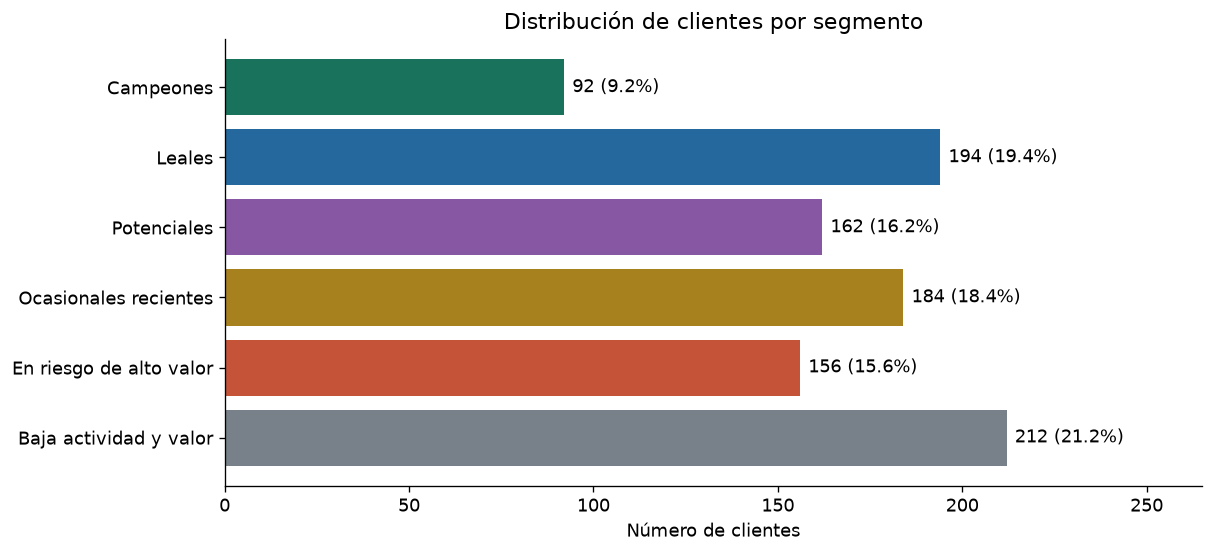

In [10]:
colores = dict(zip(segmentos, ['#19725C','#25689D','#8857A3','#A8811F','#C55338','#78818A']))
fig, ax = plt.subplots(figsize=(10,4.5), layout='constrained')
barras = ax.barh(segmentos, perfil.Clientes, color=[colores[s] for s in segmentos])
ax.bar_label(barras, labels=[f'{n} ({p:.1f}%)' for n,p in zip(perfil.Clientes,perfil['% clientes'])], padding=5)
ax.invert_yaxis()
ax.set(title='Distribución de clientes por segmento', xlabel='Número de clientes', xlim=(0,perfil.Clientes.max()*1.25))
plt.show()

Los grupos van de **9.2% a 21.2%** de la base. El volumen mayor está en Baja actividad y valor (**212 clientes**); el menor, en Campeones (**92**). La cantidad de contactos por sí sola no define dónde conviene invertir: la comparo con el valor de cada grupo.

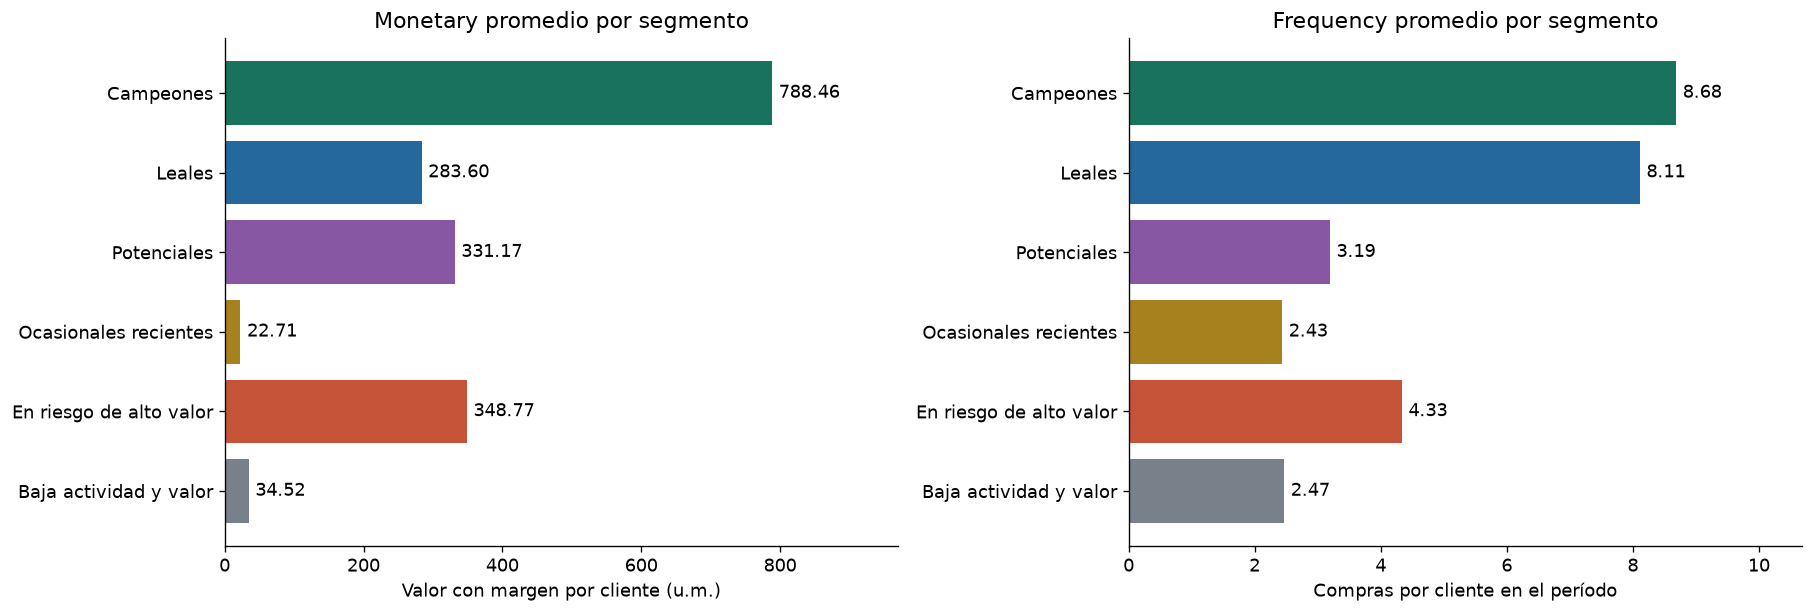

In [11]:
fig, axes = plt.subplots(1,2,figsize=(15,5),layout='constrained')
for ax,metrica,titulo,unidad in zip(axes,['Monetary','Frequency'],
        ['Monetary promedio por segmento','Frequency promedio por segmento'],
        ['Valor con margen por cliente (u.m.)','Compras por cliente en el período']):
    barras = ax.barh(segmentos, perfil[metrica], color=[colores[s] for s in segmentos])
    ax.bar_label(barras, fmt='%.2f', padding=4)
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel=unidad, xlim=(0,perfil[metrica].max()*1.23))
plt.show()

**Monetary:** Campeones lidera con **788.46 u.m. por cliente**, frente a **22.71** de Ocasionales recientes. En riesgo (**348.77**) y Potenciales (**331.17**) merecen atención aunque no sean los más frecuentes.

**Frequency:** Campeones (**8.68**) y Leales (**8.11**) compran con mayor recurrencia. Potenciales (**3.19**) ofrece una oportunidad para probar acciones de recompra. Estas diferencias describen perfiles construidos con RFM; no demuestran que las acciones propuestas funcionarán.

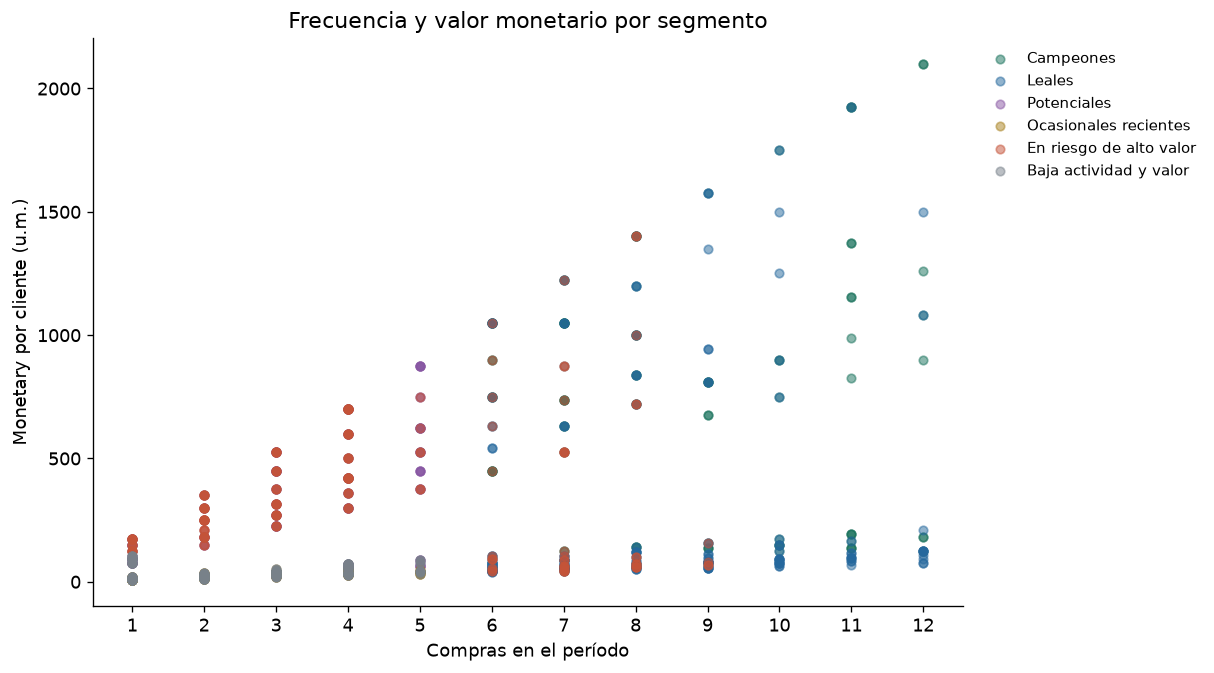

In [12]:
fig, ax = plt.subplots(figsize=(10,5.5),layout='constrained')
for segmento in segmentos:
    grupo = rfm[rfm.Segmento.eq(segmento)]
    ax.scatter(grupo.Frequency, grupo.Monetary, label=segmento,
               color=colores[segmento], alpha=.50, s=26)
ax.set(title='Frecuencia y valor monetario por segmento', xlabel='Compras en el período',
       ylabel='Monetary por cliente (u.m.)', xticks=range(1,13))
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),frameon=False,fontsize=9)
plt.show()

La dispersión muestra que clientes con la misma frecuencia pueden generar valores monetarios muy distintos. Los cinco niveles de ticket y los cocientes de margen observados producen bandas visibles. El color añade la recencia mediante el segmento: Frequency y Monetary por sí solas no explican toda la clasificación. Varios puntos se superponen, por lo que el tamaño de los grupos se lee mejor en la gráfica de conteos.

## 8. Comprobación del efecto de la categoría

Me llama la atención que ningún cliente de Electronics aparezca como Campeón o Leal. Para revisar cuánto depende este resultado de la referencia utilizada, vuelvo a calcular los puntajes dentro de cada categoría y mantengo las mismas reglas de segmentación.

Esta comparación identifica quién destaca frente a compradores de su categoría. Conservo el RFM global como resultado principal y uso esta segunda lectura para evaluar la sensibilidad de la clasificación. Si se repitieran los cortes entre percentiles, habría que revisar el método antes de continuar.

In [13]:
rfm_categoria = df.copy(deep=True)
cortes_categoria = []
for categoria, grupo in df.groupby('Product Category'):
    for variable,score in zip(variables_rfm,columnas_score):
        q = grupo[variable].quantile([.2,.4,.6,.8]).tolist()
        assert len(set(q)) == 4, f'Revisar empates de cortes: {categoria}, {variable}'
        etiquetas = [5,4,3,2,1] if variable=='Recency' else [1,2,3,4,5]
        rfm_categoria.loc[grupo.index,score] = pd.cut(grupo[variable],[-np.inf,*q,np.inf],
                                                    labels=etiquetas, right=True).astype(int)
        cortes_categoria.append([categoria,variable,*q])
rfm_categoria[columnas_score] = rfm_categoria[columnas_score].astype(int)
rfm_categoria['Segmento'] = clasificar_segmentos(rfm_categoria)
cambio = rfm.Segmento.ne(rfm_categoria.Segmento)
display(pd.DataFrame(cortes_categoria, columns=['Categoría','Variable','p20','p40','p60','p80']))
print('Clientes que cambian de segmento:', int(cambio.sum()), f'({100*cambio.mean():.1f}%)')
display(pd.crosstab(rfm.Segmento,rfm_categoria.Segmento).reindex(index=segmentos,columns=segmentos,fill_value=0)
        .rename_axis(index='Segmento global', columns='Segmento dentro de categoría'))
riesgo_categoria = pd.DataFrame({
    'Riesgo global': rfm[rfm.Segmento.eq('En riesgo de alto valor')]['Product Category'].value_counts(),
    'Riesgo relativo a categoría': rfm_categoria[rfm_categoria.Segmento.eq('En riesgo de alto valor')]['Product Category'].value_counts(),
}).fillna(0).astype(int)
display(riesgo_categoria)

,Categoría,Variable,p20,p40,p60,p80
0,Beauty,Recency,1.00,2.00,4.00,5.00
1,Beauty,Frequency,3.00,5.00,7.00,10.00
2,Beauty,Monetary,43.75,79.65,162.00,728.00
3,Clothing,Recency,2.00,5.00,7.00,10.00
4,Clothing,Frequency,2.00,4.00,6.00,7.00
5,Clothing,Monetary,31.25,60.00,105.00,525.00
6,Electronics,Recency,5.00,10.00,14.00,19.00
7,Electronics,Frequency,1.00,2.00,3.00,4.00
8,Electronics,Monetary,15.00,30.00,75.00,300.00


Clientes que cambian de segmento: 388 (38.8%)


Segmento dentro de categoría,Campeones,Leales,Potenciales,Ocasionales recientes,En riesgo de alto valor,Baja actividad y valor
Segmento global,,,,,,
Campeones,37,29,26,0,0,0
Leales,10,87,18,29,44,6
Potenciales,13,3,113,8,17,8
Ocasionales recientes,0,13,7,147,0,17
En riesgo de alto valor,5,9,24,0,110,8
Baja actividad y valor,0,19,15,35,25,118


,Riesgo global,Riesgo relativo a categoría
Product Category,,
Beauty,0,61
Clothing,72,64
Electronics,84,71


Cambian **388 clientes (38.8%)** al usar referencias por categoría. De los 156 clientes en riesgo global, **110 permanecen en riesgo y 46 salen**; otros **86 entran**, dejando 196 en la comparación por categoría. Electronics pasa de 84 a 71 casos, mientras Beauty pasa de 0 a 61.

La clasificación depende de con quién comparo a cada cliente. Además de R y F, esta sensibilidad cambia los cortes de Monetary, por lo que no atribuyo todos los movimientos al ciclo de recompra. Mantengo el modelo global para comparar el valor absoluto de la cartera, y usaría la referencia por categoría para revisar prioridades antes de una campaña. Ninguno de los dos modelos prueba abandono sin historia temporal.

## 9. Acciones comerciales y medición

Los perfiles sugieren necesidades distintas: cuidar la relación con Campeones, desarrollar la recurrencia de Potenciales y revisar el ciclo de compra antes de reactivar clientes. A partir de estas diferencias propongo las siguientes acciones. La categoría predominante orienta el diseño general; cada recomendación se adaptaría a la categoría del cliente. Las cifras de perfil son promedios por cliente.

| Segmento | Perfil observado | Acción que probaría | KPIs de éxito | Riesgo o consideración |
| --- | --- | --- | --- | --- |
| Campeones | 8.68 compras; Monetary de 788.46 u.m. | Acceso anticipado a novedades y recomendaciones complementarias a su categoría, con atención preferente. | Recompra90; CompraOtraCategoria90; MargenIncremental90. | Premiar la relación sin subsidiar compras que habrían ocurrido de todos modos. |
| Leales | 8.11 compras; ticket de 115.72 u.m. | Recomendaciones de paquetes o complementos que eleven el valor de compras ya recurrentes. | Frecuencia90; Ticket90; MargenIncremental90. | Un ticket mayor no basta si cae la recurrencia o se erosiona el margen. |
| Potenciales | 3.19 compras; ticket de 358.64 u.m. | Recordatorios de reposición cuando correspondan y recomendaciones relacionadas con su compra para desarrollar recurrencia. | Recompra90; Recurrencia90; MargenIncremental90. | No forzar la frecuencia de categorías con ciclos largos ni asumir que son clientes nuevos. |
| Ocasionales recientes | 2.43 compras; ticket de 33.02 u.m. | Seguimiento automatizado de bajo costo con contenido útil y recomendaciones accesibles; probar un paquete solo si deja contribución positiva. | Recompra90; Ticket90; MargenIncremental90. | Su ticket de 33.02 u.m. limita el costo de contacto e incentivo viable. |
| En riesgo de alto valor | 12.97 días de recencia; Monetary de 348.77 u.m. | Revisar recencia frente a categoría e historial; después, probar una invitación personalizada a volver con incentivo limitado si resulta necesario. | Reactivacion90; Frecuencia90; MargenIncremental90. | Los 12.97 días medios no confirman abandono; el 53.8% del segmento es Electronics. |
| Baja actividad y valor | 14.28 días de recencia; Monetary de 34.52 u.m. | Comunicación automatizada de baja intensidad y recomendaciones por categoría, con presupuesto acotado. | Reactivacion90; CostoReactivacion90; MargenIncremental90. | Evitar que el costo de recuperación supere la contribución; bajo valor histórico no significa valor futuro nulo. |

### Definición de los KPIs

Propongo **90 días desde la asignación** como ventana de evaluación del piloto; es una ventana propuesta para medir las acciones, distinta del período no especificado de la base. Antes de lanzar, la ajustaría al ciclo real de cada categoría. Dentro de cada segmento y categoría asignaría al azar tratamiento **T** y control **C**, con igual ventana y seguimiento. Los denominadores incluyen a todos los clientes asignados, también a quienes no compren.

| KPI | Cálculo en cada grupo, salvo donde se indica T−C | Datos adicionales necesarios |
| --- | --- | --- |
| Recompra90 | Clientes con ≥1 compra en 90 días / clientes asignados × 100. | Asignación, ID y fecha de compras posteriores. |
| CompraOtraCategoria90 | Clientes que compran una categoría distinta de su principal al inicio / clientes asignados × 100. Mide compra fuera de la principal, no una categoría nunca comprada. | Categoría inicial y categorías de las compras posteriores. |
| Frecuencia90 | Número total de compras en 90 días / clientes asignados, incluyendo ceros. | Transacciones e ID del cliente. |
| Ticket90 | Importe neto de ventas en 90 días / número de compras del período. Es un promedio por compra, no la media de tickets por cliente del perfil. | Importe neto y definición consistente de compra/devolución. |
| Recurrencia90 | Clientes con ≥2 compras en 90 días / clientes asignados × 100. | ID y fechas de compras posteriores. |
| Reactivacion90 | Clientes de un segmento de menor actividad que compran en 90 días / clientes asignados de ese segmento × 100. | Segmento inicial y compras posteriores. Es reactivación operativa, no prueba de churn previo. |
| CostoReactivacion90 | Costo total de la campaña / clientes del tratamiento que vuelven a comprar. No equivale a costo por reactivación incremental. | Costos y compradores del tratamiento. |
| MargenIncremental90 | Media por cliente de (valor con margen del período − costos adicionales de campaña) en T, menos la misma media en C. Incluir clientes sin compra y descontar cada costo una sola vez. | Valor con margen posterior, costos no incluidos ya en ese valor y asignación T/C. |

Compararía las tasas mediante **T−C en puntos porcentuales** y las medias mediante **T−C en sus unidades**, con incertidumbre y tamaño de muestra. Si no hay compras/reactivaciones, Ticket90 o CostoReactivacion90 queda **no estimable**, no cero. Las metas se fijarían con la línea base y los costos reales del piloto; con esta base no puedo estimar las tasas futuras de recompra o churn ni el efecto de las acciones propuestas.

El análisis me lleva a distinguir entre conseguir más compras y generar más valor. Por eso incluyo **margen incremental** en todos los segmentos: una campaña podría elevar la recompra y aun así resultar costosa. Para evaluarla necesitaría una línea base comparable; los promedios históricos disponibles no representan necesariamente 90 días.

El CLV permitiría ampliar la mirada hacia el valor futuro, pero aquí falta conocer el período de Monetary y estimar la retención. Por eso no lo calculo con esta base. Para estimarlo usaría un horizonte de **3 años**, sin volver a aplicar el margen ya integrado.

## 10. Decisiones que se desprenden del análisis

In [14]:
prioridades = {
    'Retener Campeones y Leales': ['Campeones','Leales'],
    'Desarrollar Potenciales': ['Potenciales'],
    'Revisar recuperación de alto valor': ['En riesgo de alto valor'],
    'Mantener contacto de bajo costo': ['Ocasionales recientes','Baja actividad y valor'],
}
filas = []
for decision, grupos in prioridades.items():
    seleccion = rfm[rfm.Segmento.isin(grupos)]
    filas.append([decision, len(seleccion), 100*len(seleccion)/len(rfm),
                  seleccion.Monetary.sum(), 100*seleccion.Monetary.sum()/rfm.Monetary.sum()])
priorizacion = pd.DataFrame(filas, columns=['Decisión','Clientes','% clientes','Monetary total','% Monetary'])
display(priorizacion)

,Decisión,Clientes,% clientes,Monetary total,% Monetary
0,Retener Campeones y Leales,286,28.60,"127,557.00",51.62
1,Desarrollar Potenciales,162,16.20,"53,650.00",21.71
2,Revisar recuperación de alto valor,156,15.60,"54,408.75",22.02
3,Mantener contacto de bajo costo,396,39.60,"11,497.25",4.65


- **Retener la base más valiosa.** Campeones y Leales son **286 clientes (28.6%)** y aportan **51.62% de Monetary**. Priorizaría servicio y personalización, comprobando el margen incremental antes de ampliar beneficios.
- **Desarrollar recurrencia en Potenciales.** Sus **162 clientes** aportan **21.71% del valor**, con el ticket más alto (**358.64 u.m.**) y **3.19 compras** de media. Probaría recomendaciones de recompra adaptadas a la categoría.
- **Revisar antes de reactivar.** En riesgo concentra **22.02% del valor** en **156 clientes**, pero **53.8% pertenece a Electronics**. Validaría el ciclo de compra antes de invertir en su recuperación; ese valor es histórico, no una pérdida ni un ingreso recuperable garantizado.
- **Controlar el costo de contacto.** Ocasionales recientes y Baja actividad y valor reúnen **396 clientes (39.6%)**, pero solo **4.65% de Monetary**. Empezaría con comunicaciones automatizadas y evaluaría si generan contribución adicional.
- **Usar RFM con contexto.** El cambio de referencia global a categoría reclasifica **38.8% de la base**. Mantendría ambas lecturas para revisar la selección del piloto, y mediría su resultado con grupos comparables. La segmentación organiza decisiones; la evidencia del piloto determinaría cuáles funcionan.

## Comprobación final

In [15]:
assert rfm['Customer ID'].is_unique and set(rfm['Customer ID']) == set(csv_original['Customer ID'])
assert perfil.Clientes.sum() == len(csv_original)
assert np.isclose(perfil['% clientes'].sum(), 100)
assert np.isclose(perfil['% Monetary'].sum(), 100)
assert np.isclose(perfil.Monetary_total.sum(), csv_original.Monetary.sum())
assert np.isclose(priorizacion['Monetary total'].sum(), csv_original.Monetary.sum())
assert df.equals(csv_original)
assert {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in rutas} == hashes_iniciales
print(f'{len(rfm):,} clientes conservados; {rfm.Segmento.nunique()} segmentos; porcentajes y Monetary conciliados.')
print('CSV y Excel originales sin modificaciones.')

1,000 clientes conservados; 6 segmentos; porcentajes y Monetary conciliados.
CSV y Excel originales sin modificaciones.


Los segmentos conservan los 1,000 clientes y el valor monetario de la base, y los archivos originales permanecen intactos. Con esta clasificación puedo justificar a quién dar prioridad y qué acción probar; conocer su efecto requiere observar las compras y el margen después de la campaña.